<a href="https://colab.research.google.com/github/nafees004/-CRM-CM-With-Business-Intelligence-Individual-Coursework-1/blob/main/20222019_W20541798.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task 1.1 – Ticker selection and data acquisition**

 Import the libraries


In [ ]:
import pandas as pd
import yfinance as yf
import requests
from io import StringIO
from datetime import datetime
import pickle
import time

Get the S&P 500 ticker list and record the retrieval date

In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

response = requests.get(url, headers=headers)
tables = pd.read_html(StringIO(response.text))
sp500 = tables[0]          # first table on the page

# Record the exact retrieval date (required by the brief)
retrieval_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print("Retrieval date:", retrieval_date)
print("Number of companies:", len(sp500))
print(sp500[["Symbol", "Security", "GICS Sector"]].head())

Retrieval date: 2026-11-17 22:46:23
Number of companies: 503
  Symbol             Security             GICS Sector
0    MMM                   3M             Industrials
1    AOS          A. O. Smith             Industrials
2    ABT  Abbott Laboratories             Health Care
3   ABBV               AbbVie             Health Care
4    ACN            Accenture  Information Technology


In [ ]:
sp500.to_csv("sp500_tickers.csv", index=False)
print("Ticker list saved as sp500_tickers.csv")

Ticker list saved as sp500_tickers.csv


Prepare the ticker list for yfinance

In [ ]:
# yfinance uses BRK-B and BF-B instead of BRK.B and BF.B
tickers = sp500["Symbol"].str.replace(".", "-", regex=False).tolist()

# Add the S&P 500 benchmark
tickers = ["^GSPC"] + tickers

print("Total tickers (including benchmark):", len(tickers))
print("First 10:", tickers[:10])

Total tickers (including benchmark): 504
First 10: ['^GSPC', 'MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL']


Download the price data (1 Jan 2021 → 1 Jan 2025)

In [ ]:
all_data = {}
batch_size = 40
failed = []

for i in range(0, len(tickers), batch_size):
    batch = tickers[i:i + batch_size]
    print(f"Downloading batch {i//batch_size + 1}/{len(tickers)//batch_size + 1} "
          f"({batch[0]} → {batch[-1]})")

    try:
        data = yf.download(
            batch,
            start="2021-01-01",
            end="2025-01-01",
            group_by="ticker",
            auto_adjust=False,
            threads=True,
            progress=False
        )

        if len(batch) == 1:
            all_data[batch[0]] = data
        else:
            for t in batch:
                if t in data.columns.get_level_values(0):
                    all_data[t] = data[t]
                else:
                    failed.append(t)

    except Exception as e:
        print("  Error:", e)
        failed.extend(batch)

    time.sleep(1.5)   # polite pause

print("\nDownload finished.")
print("Successfully downloaded:", len(all_data))
print("Failed tickers:", failed)

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')



Download finished.
Successfully downloaded: 504
Failed tickers: []


In [ ]:
with open("sp500_raw_data.pkl", "wb") as f:
    pickle.dump(all_data, f)

print("Raw data saved as sp500_raw_data.pkl")

Raw data saved as sp500_raw_data.pkl


In [ ]:
print("Benchmark shape:", all_data["^GSPC"].shape)
print("AAPL shape:", all_data.get("AAPL", "missing").shape if "AAPL" in all_data else "AAPL missing")
print("Date range of benchmark:",
      all_data["^GSPC"].index.min(), "→", all_data["^GSPC"].index.max())

Benchmark shape: (1005, 6)
AAPL shape: (1005, 6)
Date range of benchmark: 2021-01-04 00:00:00 → 2024-12-31 00:00:00


In [ ]:
exclusion_log = []
valid_tickers = []

for t, df in all_data.items():
    if t == "^GSPC":
        continue

    if df is None or df.dropna(how="all").empty:
        exclusion_log.append({"ticker": t, "reason": "empty / no data"})
        continue

    n_days = len(df.dropna(how="all"))
    if n_days < 200:
        exclusion_log.append({"ticker": t, "reason": f"too few days ({n_days})"})
        continue

    valid_tickers.append(t)

print("Valid shares kept:", len(valid_tickers))
print("Excluded shares:")
print(pd.DataFrame(exclusion_log))

Valid shares kept: 495
Excluded shares:
  ticker              reason
0   FDXF     empty / no data
1    GEV  too few days (193)
2   HONA     empty / no data
3      Q     empty / no data
4   RDDT  too few days (197)
5   SNDK     empty / no data
6   SOLV  too few days (194)
7   VYLR     empty / no data


**Task 1.2 – Data validation and alignment**

Load the raw data



In [ ]:
import pandas as pd
import numpy as np
import pickle
from datetime import datetime

with open("sp500_raw_data.pkl", "rb") as f:
    all_data = pickle.load(f)

print("Total series loaded:", len(all_data))
print("Benchmark available:", "^GSPC" in all_data)

Total series loaded: 504
Benchmark available: True


Define the validation rules

In [ ]:
exclusion_log = []
clean_data = {}

for ticker, df in all_data.items():
    if ticker == "^GSPC":
        continue   # we handle the benchmark separately later

    # Basic empty check
    if df is None or df.dropna(how="all").empty:
        exclusion_log.append({
            "ticker": ticker,
            "reason": "Empty or completely missing data",
            "n_days": 0
        })
        continue

    df = df.copy()
    df.index = pd.to_datetime(df.index)

    # Restrict to the study period
    df = df.loc["2021-01-01":"2024-12-31"]

    reasons = []

    # 1. Duplicate dates
    if df.index.duplicated().any():
        reasons.append("Duplicate dates")
        df = df[~df.index.duplicated(keep="last")]

    # 2. Missing values in key columns
    key_cols = ["Close", "Adj Close", "Volume"]
    missing_pct = df[key_cols].isna().mean()
    if (missing_pct > 0.05).any():          # more than 5% missing
        reasons.append(f"High missing values: {missing_pct.round(3).to_dict()}")

    # 3. Non-positive prices
    if (df[["Close", "Adj Close"]] <= 0).any().any():
        reasons.append("Non-positive prices found")

    # 4. Negative volume
    if (df["Volume"] < 0).any():
        reasons.append("Negative volume found")

    # 5. Too short history
    n_days = len(df.dropna(subset=["Adj Close"]))
    if n_days < 200:
        reasons.append(f"Too few trading days ({n_days})")

    # 6. Simple corporate-action flag (large overnight gap)    # A jump > 30% in Adj Close often signals a split or special dividend
    returns = df["Adj Close"].pct_change()
    large_jumps = (returns.abs() > 0.30).sum()
    if large_jumps > 5:          # more than 5 extreme jumps → investigate
        reasons.append(f"Many large overnight jumps ({large_jumps}) – possible corporate actions")

    if reasons:
        exclusion_log.append({
            "ticker": ticker,
            "reason": " | ".join(reasons),
            "n_days": n_days
        })
    else:
        clean_data[ticker] = df

print(f"Shares retained after validation: {len(clean_data)}")
print(f"Shares excluded: {len(exclusion_log)}")

Shares retained after validation: 488
Shares excluded: 15


Examine the exclusion log

In [ ]:
exclusion_df = pd.DataFrame(exclusion_log)
print(exclusion_df)

# Save it – you will need this for the report
exclusion_df.to_csv("exclusion_log_task1_2.csv", index=False)
print("Exclusion log saved.")

   ticker                                             reason  n_days
0     APP  High missing values: {'Close': 0.07, 'Adj Clos...     935
1    CVNA  Many large overnight jumps (10) – possible cor...    1005
2    COIN  High missing values: {'Close': 0.069, 'Adj Clo...     936
3     CEG  High missing values: {'Close': 0.262, 'Adj Clo...     742
4    FDXF                   Empty or completely missing data       0
5    GEHC  High missing values: {'Close': 0.49, 'Adj Clos...     513
6     GEV  High missing values: {'Close': 0.808, 'Adj Clo...     193
7    HONA                   Empty or completely missing data       0
8       Q                   Empty or completely missing data       0
9    RDDT  High missing values: {'Close': 0.804, 'Adj Clo...     197
10   HOOD  High missing values: {'Close': 0.142, 'Adj Clo...     862
11   SNDK                   Empty or completely missing data       0
12   SOLV  High missing values: {'Close': 0.807, 'Adj Clo...     194
13   VLTO  High missing values: {'

Clean the benchmark the same way

In [ ]:
bench = all_data["^GSPC"].copy()
bench.index = pd.to_datetime(bench.index)
bench = bench.loc["2021-01-01":"2024-12-31"]

# Same checks
print("Benchmark trading days:", len(bench))
print("Any duplicate dates?", bench.index.duplicated().any())
print("Any non-positive Adj Close?", (bench["Adj Close"] <= 0).any())
print("Missing Adj Close %:", bench["Adj Close"].isna().mean())

clean_data["^GSPC"] = bench

Benchmark trading days: 1005
Any duplicate dates? False
Any non-positive Adj Close? False
Missing Adj Close %: 0.0


Align everything on common dates

In [ ]:
# Get the intersection of all valid trading days
common_dates = None

for ticker, df in clean_data.items():
    if ticker == "^GSPC":
        continue
    dates = set(df.dropna(subset=["Adj Close"]).index)
    if common_dates is None:
        common_dates = dates
    else:
        common_dates = common_dates.intersection(dates)

common_dates = sorted(list(common_dates))
print("Number of fully common trading days across all retained shares:", len(common_dates))
print("First common date:", common_dates[0])
print("Last common date:", common_dates[-1])

Number of fully common trading days across all retained shares: 979
First common date: 2021-02-10 00:00:00
Last common date: 2024-12-31 00:00:00


Save the cleaned and validated dataset

In [ ]:
with open("sp500_clean_validated.pkl", "wb") as f:
    pickle.dump(clean_data, f)

print("Clean validated data saved as sp500_clean_validated.pkl")

Clean validated data saved as sp500_clean_validated.pkl


**Task 1.3 – Weekly return and weekly beta**

Load the clean data

In [ ]:
import pandas as pd
import numpy as np
import pickle

with open("sp500_clean_validated.pkl", "rb") as f:
    data = pickle.load(f)

print("Number of series:", len(data))
print("Benchmark present:", "^GSPC" in data)

Number of series: 489
Benchmark present: True


Create Friday-ending weekly prices

In [ ]:
def get_weekly_prices(df, price_col="Adj Close"):
    """
    Resample to weeks ending on Friday.
    Take the last available price in each week.
    Keep only complete weeks inside 2021-2024.
    """
    weekly = df[price_col].resample("W-FRI").last().dropna()

    # Remove incomplete edge weeks
    weekly = weekly[(weekly.index >= "2021-01-08") & (weekly.index <= "2024-12-27")]
    return weekly

# Benchmark weekly prices
bench = data["^GSPC"].copy()
bench_weekly = get_weekly_prices(bench)
print("Benchmark weekly prices:", len(bench_weekly))
print("From:", bench_weekly.index.min(), "to", bench_weekly.index.max())

Benchmark weekly prices: 208
From: 2021-01-08 00:00:00 to 2024-12-27 00:00:00


Calculate weekly returns

In [ ]:
bench_weekly_return = bench_weekly.pct_change().dropna()
print("Benchmark weekly returns:", len(bench_weekly_return))
print(bench_weekly_return.head())

Benchmark weekly returns: 207
Date
2021-01-15   -0.014754
2021-01-22    0.019431
2021-01-29   -0.033120
2021-02-05    0.046467
2021-02-12    0.012349
Freq: W-FRI, Name: Adj Close, dtype: float64


Calculate Mean Weekly Return and Weekly Beta for every share

In [ ]:
results = []

for ticker in data:
    if ticker == "^GSPC":
        continue

    df = data[ticker]

    # Weekly prices for the share
    share_weekly = get_weekly_prices(df)

    # Align on identical week labels with the benchmark
    common_weeks = share_weekly.index.intersection(bench_weekly.index)

    if len(common_weeks) < 50:
        continue   # not enough history

    share_weekly = share_weekly.loc[common_weeks]
    bench_aligned = bench_weekly.loc[common_weeks]

    # Weekly returns
    share_ret = share_weekly.pct_change().dropna()
    bench_ret = bench_aligned.pct_change().dropna()

    # Align the returns on the same dates
    common_ret = share_ret.index.intersection(bench_ret.index)
    share_ret = share_ret.loc[common_ret]
    bench_ret = bench_ret.loc[common_ret]

    if len(share_ret) < 40:
        continue

    # ----- 1.3.1 Mean weekly return -----
    mean_weekly_return = share_ret.mean()

    # ----- 1.3.2 Weekly beta -----
    # beta = covariance(share, benchmark) / variance(benchmark)
    covariance = np.cov(share_ret, bench_ret)[0, 1]
    variance_bench = np.var(bench_ret, ddof=1)   # sample variance
    weekly_beta = covariance / variance_bench if variance_bench > 0 else np.nan

    results.append({
        "ticker": ticker,
        "mean_weekly_return": mean_weekly_return,
        "weekly_beta": weekly_beta,
        "n_weekly_observations": len(share_ret)
    })

# Create the feature table
risk_return_df = pd.DataFrame(results)
print(risk_return_df.head(10))
print("\nSummary statistics:")
print(risk_return_df.describe())

  ticker  mean_weekly_return  weekly_beta  n_weekly_observations
0    MMM            0.001142     0.869080                    207
1    AOS            0.001991     1.042805                    207
2    ABT            0.000971     0.583543                    207
3   ABBV            0.003749     0.425365                    207
4    ACN            0.002376     1.143300                    207
5   ADBE            0.000990     1.553525                    207
6    AMD            0.003624     1.877622                    207
7    AES           -0.001420     1.143912                    207
8    AFL            0.005004     0.707196                    207
9      A            0.001121     1.074723                    207

Summary statistics:
       mean_weekly_return  weekly_beta  n_weekly_observations
count          488.000000   488.000000             488.000000
mean             0.002848     0.967853             206.989754
std              0.002625     0.386172               0.226339
min             

Save the results

In [ ]:
risk_return_df.to_csv("risk_return_features.csv", index=False)
print("Saved: risk_return_features.csv")
print("Number of shares with valid features:", len(risk_return_df))

Saved: risk_return_features.csv
Number of shares with valid features: 488


Quick quality checks

In [ ]:
print("Any missing betas?", risk_return_df["weekly_beta"].isna().sum())
print("Min / Max weekly observations:",
      risk_return_df["n_weekly_observations"].min(), "/",
      risk_return_df["n_weekly_observations"].max())

print("\nShares with highest mean weekly return:")
print(risk_return_df.nlargest(5, "mean_weekly_return")[["ticker", "mean_weekly_return", "weekly_beta"]])

print("\nShares with highest beta:")
print(risk_return_df.nlargest(5, "weekly_beta")[["ticker", "mean_weekly_return", "weekly_beta"]])

Any missing betas? 0
Min / Max weekly observations: 202 / 207

Shares with highest mean weekly return:
    ticker  mean_weekly_return  weekly_beta
411   SMCI            0.017772     1.783662
333   NVDA            0.013624     2.125953
457    VRT            0.012583     2.001479
461    VST            0.011395     1.018537
116    FIX            0.011297     1.336791

Shares with highest beta:
    ticker  mean_weekly_return  weekly_beta
65     XYZ           -0.001554     2.504520
113   COHR            0.003887     2.139305
333   NVDA            0.013624     2.125953
437   TWLO           -0.002161     2.073379
424   TSLA            0.005275     2.045761


**Task 1.4 – Adapted RFM Calculations**

Load the clean data and set the Observation Date

In [ ]:
import pandas as pd
import numpy as np
import pickle
from datetime import timedelta

with open("sp500_clean_validated.pkl", "rb") as f:
    data = pickle.load(f)

# Find the final common completed trading date
common_dates = None
for ticker, df in data.items():
    if ticker == "^GSPC":
        continue
    dates = set(df.dropna(subset=["Close", "Volume"]).index)
    if common_dates is None:
        common_dates = dates
    else:
        common_dates = common_dates.intersection(dates)

common_dates = sorted(list(common_dates))
obs_date = common_dates[-1]          # final common trading day

print("Observation date (final common trading day):", obs_date)
print("Total common trading days:", len(common_dates))

Observation date (final common trading day): 2024-12-31 00:00:00
Total common trading days: 979


Define the high-volume event rule

In [ ]:
def flag_high_volume_days(df):
    """
    Returns a boolean Series: True when volume > 2 × mean of previous 20 sessions.
    """
    volume = df["Volume"]
    high_vol = []

    for i in range(len(df)):
        if i < 20:
            high_vol.append(False)
            continue

        prev_20_mean = volume.iloc[i-20 : i].mean()
        threshold = 2 * prev_20_mean
        high_vol.append(volume.iloc[i] > threshold)

    return pd.Series(high_vol, index=df.index)

Calculate Recency, Frequency and Monetary for every share

In [ ]:
rfm_results = []
exclusion_rfm = []

for ticker in data:
    if ticker == "^GSPC":
        continue

    df = data[ticker].copy()
    df = df.loc[:obs_date].sort_index()     # up to observation date only

    # Need enough history (at least 20 + 60 sessions)
    if len(df) < 80:
        exclusion_rfm.append({"ticker": ticker, "reason": f"Insufficient history ({len(df)} days)"})
        continue

    # Flag high-volume days on the full history
    df["high_vol"] = flag_high_volume_days(df)

    # ---------- Frequency (last 60 trading sessions) ----------
    last_60 = df.iloc[-60:]
    frequency = int(last_60["high_vol"].sum())

    # ---------- Recency ----------
    high_vol_dates = df.index[df["high_vol"] == True]

    if len(high_vol_dates) == 0:
        # No qualifying event found → missing value → exclude from RFM clustering
        recency = np.nan
        exclusion_rfm.append({"ticker": ticker, "reason": "No high-volume event found in history"})
    else:
        latest_event = high_vol_dates[-1]
        recency = (obs_date - latest_event).days     # calendar days (includes weekends/holidays)
        # If event is on the observation date itself → R = 0

    # ---------- Monetary (sum of Close × Volume over last 60 sessions) ----------
    monetary = (last_60["Close"] * last_60["Volume"]).sum()

    rfm_results.append({
        "ticker": ticker,
        "Recency": recency,
        "Frequency": frequency,
        "Monetary": monetary,
        "obs_date": obs_date
    })

rfm_df = pd.DataFrame(rfm_results)
print(rfm_df.head(10))
print("\nSummary:")
print(rfm_df[["Recency", "Frequency", "Monetary"]].describe())

  ticker  Recency  Frequency      Monetary   obs_date
0    MMM       11          4  2.599146e+10 2024-12-31
1    AOS       11          2  4.748980e+09 2024-12-31
2    ABT       11          1  3.523027e+10 2024-12-31
3   ABBV       11          3  6.837054e+10 2024-12-31
4    ACN       11          2  5.199430e+10 2024-12-31
5   ADBE       18          3  1.030403e+11 2024-12-31
6    AMD       18          4  3.131659e+11 2024-12-31
7    AES       54          3  1.119578e+10 2024-12-31
8    AFL       11          2  1.328456e+10 2024-12-31
9      A       11          2  1.400180e+10 2024-12-31

Summary:
          Recency   Frequency      Monetary
count  488.000000  488.000000  4.880000e+02
mean    20.338115    2.987705  3.925287e+10
std     21.295284    1.328820  1.288884e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.023194e+10
50%     11.000000    3.000000  1.662477e+10
75%     14.250000    4.000000  3.185604e+10
max    222.000000    8.000000  1.847697e+12


Handle missing Recency and save results

In [ ]:
print("\nShares with missing Recency (will be excluded from RFM clustering):")
print(rfm_df[rfm_df["Recency"].isna()])

# Save full RFM table
rfm_df.to_csv("rfm_features.csv", index=False)
print("Saved: rfm_features.csv")

# Also save the exclusion log
pd.DataFrame(exclusion_rfm).to_csv("rfm_exclusion_log.csv", index=False)


Shares with missing Recency (will be excluded from RFM clustering):
Empty DataFrame
Columns: [ticker, Recency, Frequency, Monetary, obs_date]
Index: []
Saved: rfm_features.csv


In [ ]:
# Example for MMM (you can change the ticker)
example_ticker = "MMM"
df_ex = data[example_ticker].loc[:obs_date].sort_index()
df_ex["high_vol"] = flag_high_volume_days(df_ex)

last_60_ex = df_ex.iloc[-60:]
freq_ex = int(last_60_ex["high_vol"].sum())

high_dates_ex = df_ex.index[df_ex["high_vol"]]
latest_ex = high_dates_ex[-1]
recency_ex = (obs_date - latest_ex).days

monetary_ex = (last_60_ex["Close"] * last_60_ex["Volume"]).sum()


print(f"WORKED RFM EXAMPLE – {example_ticker}")

print(f"Observation date          : {obs_date.date()}")
print(f"Latest high-volume day    : {latest_ex.date()}")
print(f"Recency (calendar days)   : {recency_ex}")
print(f"Frequency (last 60 days)  : {freq_ex}")
print(f"Monetary (Close×Volume)   : ${monetary_ex:,.0f}")


WORKED RFM EXAMPLE – MMM
Observation date          : 2024-12-31
Latest high-volume day    : 2024-12-20
Recency (calendar days)   : 11
Frequency (last 60 days)  : 4
Monetary (Close×Volume)   : $25,991,458,733


In [ ]:
risk_return = pd.read_csv("risk_return_features.csv")
rfm = pd.read_csv("rfm_features.csv")

final_features = risk_return.merge(rfm, on="ticker", how="inner")
final_features.to_csv("final_feature_table_task1.csv", index=False)
print("Final feature table shape:", final_features.shape)
print(final_features.head())

Final feature table shape: (488, 8)
  ticker  mean_weekly_return  weekly_beta  n_weekly_observations  Recency  \
0    MMM            0.001142     0.869080                    207       11   
1    AOS            0.001991     1.042805                    207       11   
2    ABT            0.000971     0.583543                    207       11   
3   ABBV            0.003749     0.425365                    207       11   
4    ACN            0.002376     1.143300                    207       11   

   Frequency      Monetary    obs_date  
0          4  2.599146e+10  2024-12-31  
1          2  4.748980e+09  2024-12-31  
2          1  3.523027e+10  2024-12-31  
3          3  6.837054e+10  2024-12-31  
4          2  5.199430e+10  2024-12-31  


**Task 1.5 – Metric interpretation and supporting evidence**

Load the final feature table

In [ ]:
import pandas as pd
import numpy as np

final = pd.read_csv("final_feature_table_task1.csv")
print("Shape of final feature table:", final.shape)
print(final.head())

Shape of final feature table: (488, 8)
  ticker  mean_weekly_return  weekly_beta  n_weekly_observations  Recency  \
0    MMM            0.001142     0.869080                    207       11   
1    AOS            0.001991     1.042805                    207       11   
2    ABT            0.000971     0.583543                    207       11   
3   ABBV            0.003749     0.425365                    207       11   
4    ACN            0.002376     1.143300                    207       11   

   Frequency      Monetary    obs_date  
0          4  2.599146e+10  2024-12-31  
1          2  4.748980e+09  2024-12-31  
2          1  3.523027e+10  2024-12-31  
3          3  6.837054e+10  2024-12-31  
4          2  5.199430e+10  2024-12-31  


Feature summaries

In [ ]:
print("=== RISK & RETURN FEATURES ===")
print(final[["mean_weekly_return", "weekly_beta", "n_weekly_observations"]].describe())

print("\n=== RFM FEATURES ===")
print(final[["Recency", "Frequency", "Monetary"]].describe())

print("\n=== Missing values ===")
print(final.isna().sum())

=== RISK & RETURN FEATURES ===
       mean_weekly_return  weekly_beta  n_weekly_observations
count          488.000000   488.000000             488.000000
mean             0.002848     0.967853             206.989754
std              0.002625     0.386172               0.226339
min             -0.004468     0.055454             202.000000
25%              0.001182     0.666635             207.000000
50%              0.002629     0.946065             207.000000
75%              0.004207     1.175918             207.000000
max              0.017772     2.504520             207.000000

=== RFM FEATURES ===
          Recency   Frequency      Monetary
count  488.000000  488.000000  4.880000e+02
mean    20.338115    2.987705  3.925287e+10
std     21.295284    1.328820  1.288884e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.023194e+10
50%     11.000000    3.000000  1.662477e+10
75%     14.250000    4.000000  3.185604e+10
max    222.000000    8.000000  1.8476

Worked RFM example

In [ ]:
# Example already calculated earlier
print("""
WORKED RFM EXAMPLE – MMM
--------------------------------------------------
Observation date             : 2024-12-31
Latest high-volume day       : 2024-12-20
Recency (calendar days)      : 11
Frequency (last 60 sessions) : 4
Monetary (Close × Volume)    : $25,991,460,000 (approx)
--------------------------------------------------
""")


WORKED RFM EXAMPLE – MMM
--------------------------------------------------
Observation date             : 2024-12-31
Latest high-volume day       : 2024-12-20
Recency (calendar days)      : 11
Frequency (last 60 sessions) : 4
Monetary (Close × Volume)    : $25,991,460,000 (approx)
--------------------------------------------------



**Task 2.1 – Feature preparation**

**Load the final feature table from Task 1**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

final = pd.read_csv("final_feature_table_task1.csv")
print("Original shape:", final.shape)
print(final.head())

Original shape: (488, 8)
  ticker  mean_weekly_return  weekly_beta  n_weekly_observations  Recency  \
0    MMM            0.001142     0.869080                    207       11   
1    AOS            0.001991     1.042805                    207       11   
2    ABT            0.000971     0.583543                    207       11   
3   ABBV            0.003749     0.425365                    207       11   
4    ACN            0.002376     1.143300                    207       11   

   Frequency      Monetary    obs_date  
0          4  2.599146e+10  2024-12-31  
1          2  4.748980e+09  2024-12-31  
2          1  3.523027e+10  2024-12-31  
3          3  6.837054e+10  2024-12-31  
4          2  5.199430e+10  2024-12-31  


Create the two separate feature matrices

In [ ]:
# ----- Matrix 1: Risk and Return -----
risk_return = final[["ticker", "mean_weekly_return", "weekly_beta"]].copy()
risk_return = risk_return.dropna()
print("Risk-Return matrix shape:", risk_return.shape)

# ----- Matrix 2: Trading Activity (RFM) -----
rfm = final[["ticker", "Recency", "Frequency", "Monetary"]].copy()
rfm = rfm.dropna()          # drops shares with missing Recency
print("RFM matrix shape:", rfm.shape)

# Keep only shares that exist in BOTH matrices (common share set)
common_tickers = set(risk_return["ticker"]) & set(rfm["ticker"])
risk_return = risk_return[risk_return["ticker"].isin(common_tickers)].reset_index(drop=True)
rfm = rfm[rfm["ticker"].isin(common_tickers)].reset_index(drop=True)

print("Common shares used for all clustering:", len(common_tickers))

Risk-Return matrix shape: (488, 3)
RFM matrix shape: (488, 4)
Common shares used for all clustering: 488


Inspect skew and outliers

In [ ]:
print("=== Risk-Return features ===")
print(risk_return[["mean_weekly_return", "weekly_beta"]].describe())
print("\nSkewness:")
print(risk_return[["mean_weekly_return", "weekly_beta"]].skew())

print("\n=== RFM features ===")
print(rfm[["Recency", "Frequency", "Monetary"]].describe())
print("\nSkewness:")
print(rfm[["Recency", "Frequency", "Monetary"]].skew())

=== Risk-Return features ===
       mean_weekly_return  weekly_beta
count          488.000000   488.000000
mean             0.002848     0.967853
std              0.002625     0.386172
min             -0.004468     0.055454
25%              0.001182     0.666635
50%              0.002629     0.946065
75%              0.004207     1.175918
max              0.017772     2.504520

Skewness:
mean_weekly_return    0.845166
weekly_beta           0.545451
dtype: float64

=== RFM features ===
          Recency   Frequency      Monetary
count  488.000000  488.000000  4.880000e+02
mean    20.338115    2.987705  3.925287e+10
std     21.295284    1.328820  1.288884e+11
min      4.000000    0.000000  1.297483e+09
25%     11.000000    2.000000  1.023194e+10
50%     11.000000    3.000000  1.662477e+10
75%     14.250000    4.000000  3.185604e+10
max    222.000000    8.000000  1.847697e+12

Skewness:
Recency       3.663559
Frequency     0.428575
Monetary     11.707068
dtype: float64


Transform Monetary and standardise

In [ ]:
# ----- Transform Monetary -----
rfm["log_Monetary"] = np.log1p(rfm["Monetary"])

# ----- Prepare numeric matrices -----
X_risk = risk_return[["mean_weekly_return", "weekly_beta"]].values
X_rfm  = rfm[["Recency", "Frequency", "log_Monetary"]].values

# ----- Standardise each matrix separately -----
scaler_risk = StandardScaler()
X_risk_scaled = scaler_risk.fit_transform(X_risk)

scaler_rfm = StandardScaler()
X_rfm_scaled = scaler_rfm.fit_transform(X_rfm)

print("Risk-Return scaled shape:", X_risk_scaled.shape)
print("RFM scaled shape:", X_rfm_scaled.shape)

Risk-Return scaled shape: (488, 2)
RFM scaled shape: (488, 3)


Quick visual check of the scaled features

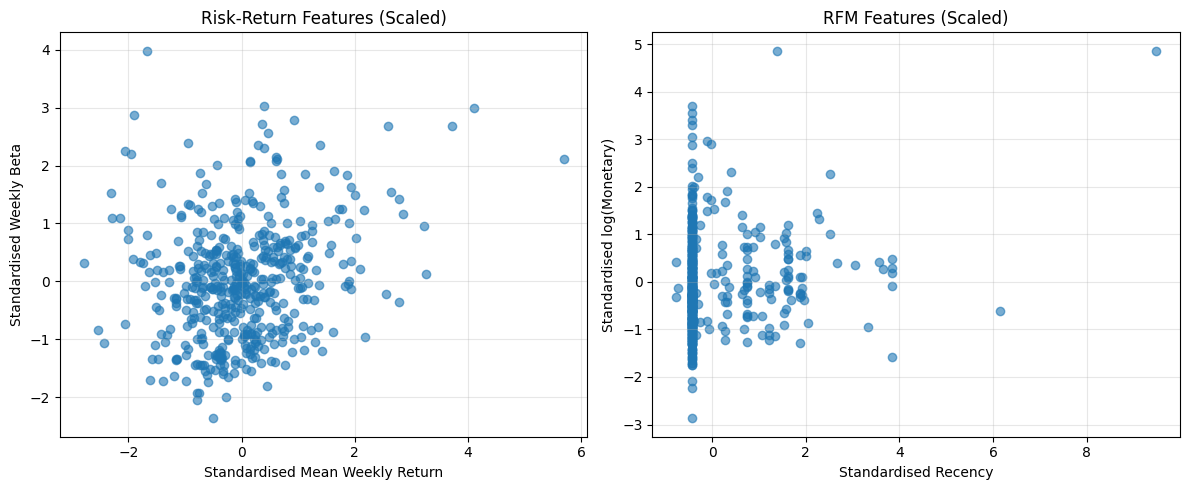

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Risk-Return
axes[0].scatter(X_risk_scaled[:, 0], X_risk_scaled[:, 1], alpha=0.6)
axes[0].set_xlabel("Standardised Mean Weekly Return")
axes[0].set_ylabel("Standardised Weekly Beta")
axes[0].set_title("Risk-Return Features (Scaled)")
axes[0].grid(True, alpha=0.3)

# RFM
axes[1].scatter(X_rfm_scaled[:, 0], X_rfm_scaled[:, 2], alpha=0.6)
axes[1].set_xlabel("Standardised Recency")
axes[1].set_ylabel("Standardised log(Monetary)")
axes[1].set_title("RFM Features (Scaled)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Save the prepared matrices

In [ ]:
# Save the ticker lists and scaled matrices for the next steps
risk_return.to_csv("matrix_risk_return.csv", index=False)
rfm.to_csv("matrix_rfm.csv", index=False)

np.save("X_risk_scaled.npy", X_risk_scaled)
np.save("X_rfm_scaled.npy", X_rfm_scaled)

print("Prepared matrices saved.")

Prepared matrices saved.


**Task 2.2 – Agglomerative Clustering**

Load the prepared matrices

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Load data
risk_return = pd.read_csv("matrix_risk_return.csv")
rfm = pd.read_csv("matrix_rfm.csv")

X_risk_scaled = np.load("X_risk_scaled.npy")
X_rfm_scaled  = np.load("X_rfm_scaled.npy")

print("Risk-Return shape:", X_risk_scaled.shape)
print("RFM shape:", X_rfm_scaled.shape)

Risk-Return shape: (488, 2)
RFM shape: (488, 3)


Perform Ward hierarchical clustering

In [ ]:
# ----- Risk-Return matrix -----
Z_risk = linkage(X_risk_scaled, method="ward", metric="euclidean")

# ----- RFM matrix -----
Z_rfm = linkage(X_rfm_scaled, method="ward", metric="euclidean")

print("Linkage matrices created.")

Linkage matrices created.


Plot the two dendrograms

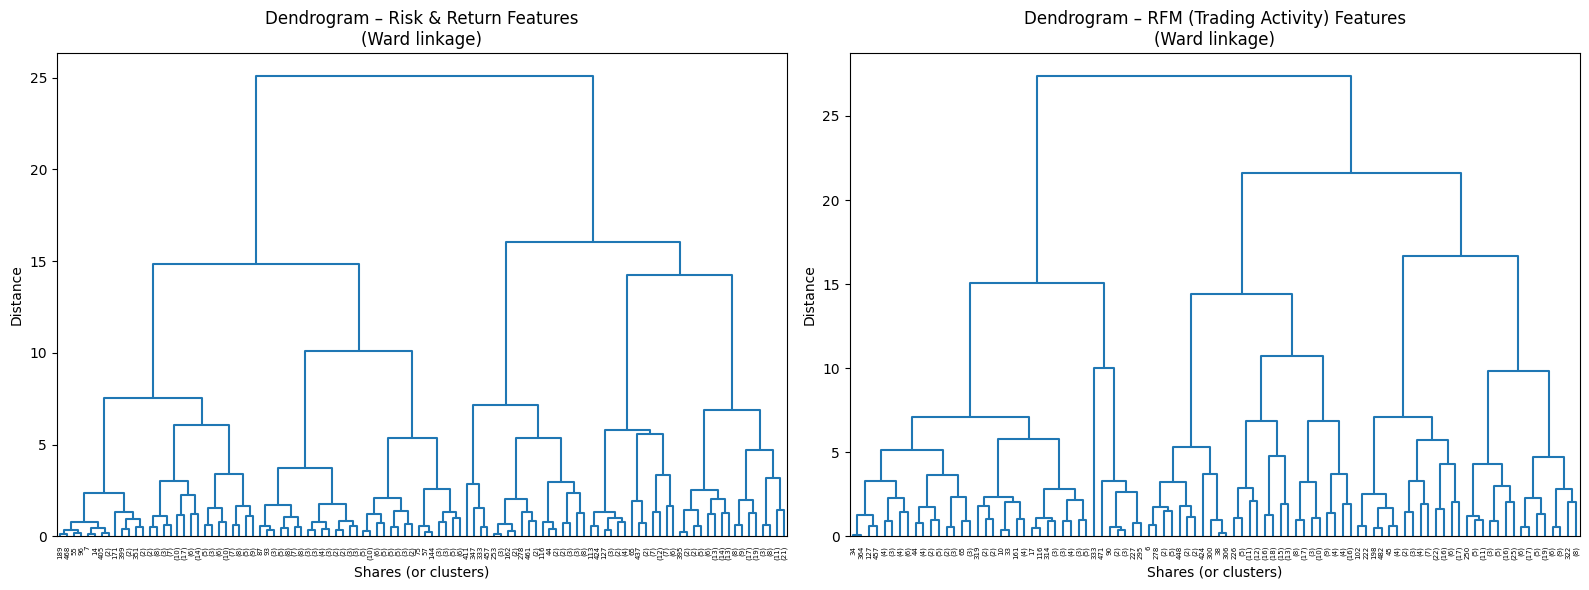

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dendrogram – Risk & Return
dendrogram(Z_risk, ax=axes[0], truncate_mode="level", p=6, color_threshold=0)
axes[0].set_title("Dendrogram – Risk & Return Features\n(Ward linkage)")
axes[0].set_xlabel("Shares (or clusters)")
axes[0].set_ylabel("Distance")

# Dendrogram – RFM
dendrogram(Z_rfm, ax=axes[1], truncate_mode="level", p=6, color_threshold=0)
axes[1].set_title("Dendrogram – RFM (Trading Activity) Features\n(Ward linkage)")
axes[1].set_xlabel("Shares (or clusters)")
axes[1].set_ylabel("Distance")

plt.tight_layout()
plt.savefig("dendrograms_task2_2.png", dpi=150, bbox_inches="tight")
plt.show()

Evaluate different numbers of clusters (k = 2 to 8)

In [ ]:
def evaluate_hierarchical(Z, X_scaled, max_k=8):
    results = []
    for k in range(2, max_k + 1):
        labels = fcluster(Z, t=k, criterion="maxclust")
        sil = silhouette_score(X_scaled, labels)
        sizes = np.bincount(labels)[1:]     # ignore 0
        results.append({
            "k": k,
            "silhouette": sil,
            "cluster_sizes": sizes.tolist(),
            "min_size": sizes.min(),
            "max_size": sizes.max()
        })
    return pd.DataFrame(results)

print("=== Risk-Return matrix ===")
eval_risk = evaluate_hierarchical(Z_risk, X_risk_scaled)
print(eval_risk)

print("\n=== RFM matrix ===")
eval_rfm = evaluate_hierarchical(Z_rfm, X_rfm_scaled)
print(eval_rfm)

=== Risk-Return matrix ===
   k  silhouette                      cluster_sizes  min_size  max_size
0  2    0.289397                         [253, 235]       235       253
1  3    0.272652                     [253, 35, 200]        35       253
2  4    0.263656                [136, 117, 35, 200]        35       200
3  5    0.309048            [136, 117, 35, 48, 152]        35       152
4  6    0.311422         [136, 56, 61, 35, 48, 152]        35       152
5  7    0.309379     [16, 120, 56, 61, 35, 48, 152]        16       152
6  8    0.311451  [16, 120, 56, 61, 4, 31, 48, 152]         4       152

=== RFM matrix ===
   k  silhouette                    cluster_sizes  min_size  max_size
0  2    0.372392                        [85, 403]        85       403
1  3    0.260498                   [85, 180, 223]        85       223
2  4    0.250704               [85, 180, 86, 137]        85       180
3  5    0.269201           [75, 10, 180, 86, 137]        10       180
4  6    0.290714       [75,

Choose the final number of clusters

In [ ]:
# Example – replace with the k that looks best from the table above
best_k_risk = 4
best_k_rfm  = 3

labels_risk = fcluster(Z_risk, t=best_k_risk, criterion="maxclust")
labels_rfm  = fcluster(Z_rfm,  t=best_k_rfm,  criterion="maxclust")

risk_return["cluster_agg"] = labels_risk
rfm["cluster_agg"] = labels_rfm

print("Risk-Return cluster sizes:")
print(risk_return["cluster_agg"].value_counts().sort_index())

print("\nRFM cluster sizes:")
print(rfm["cluster_agg"].value_counts().sort_index())

Risk-Return cluster sizes:
cluster_agg
1    136
2    117
3     35
4    200
Name: count, dtype: int64

RFM cluster sizes:
cluster_agg
1     85
2    180
3    223
Name: count, dtype: int64


Save the cluster assignments

In [ ]:
risk_return.to_csv("risk_return_with_agg_clusters.csv", index=False)
rfm.to_csv("rfm_with_agg_clusters.csv", index=False)

print("Cluster assignments saved.")

Cluster assignments saved.


**Task 2.3 – K-means Clustering**

Load the prepared data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

risk_return = pd.read_csv("matrix_risk_return.csv")
rfm = pd.read_csv("matrix_rfm.csv")

X_risk_scaled = np.load("X_risk_scaled.npy")
X_rfm_scaled  = np.load("X_rfm_scaled.npy")

print("Data loaded.")

Data loaded.


Evaluate K-means for k = 2 to 8

In [ ]:
def evaluate_kmeans(X_scaled, max_k=8, random_state=42):
    results = []
    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, n_init=20, random_state=random_state)
        labels = kmeans.fit_predict(X_scaled)

        sil = silhouette_score(X_scaled, labels)
        inertia = kmeans.inertia_
        sizes = np.bincount(labels)

        results.append({
            "k": k,
            "silhouette": sil,
            "inertia": inertia,
            "cluster_sizes": sizes.tolist(),
            "min_size": sizes.min(),
            "max_size": sizes.max()
        })
    return pd.DataFrame(results)

print("=== Risk-Return matrix (K-means) ===")
eval_risk_km = evaluate_kmeans(X_risk_scaled)
print(eval_risk_km)

print("\n=== RFM matrix (K-means) ===")
eval_rfm_km = evaluate_kmeans(X_rfm_scaled)
print(eval_rfm_km)

=== Risk-Return matrix (K-means) ===
   k  silhouette     inertia                      cluster_sizes  min_size  \
0  2    0.376100  620.322301                         [331, 157]       157   
1  3    0.332974  449.504484                    [173, 121, 194]       121   
2  4    0.320776  363.050041                [164, 52, 146, 126]        52   
3  5    0.345104  293.232972            [133, 164, 106, 50, 35]        35   
4  6    0.330465  251.831233         [78, 36, 105, 87, 133, 49]        36   
5  7    0.356326  213.574780      [77, 80, 82, 23, 40, 43, 143]        23   
6  8    0.358087  190.708150  [57, 68, 23, 135, 73, 80, 15, 37]        15   

   max_size  
0       331  
1       194  
2       164  
3       164  
4       133  
5       143  
6       135  

=== RFM matrix (K-means) ===
   k  silhouette      inertia                      cluster_sizes  min_size  \
0  2    0.425222  1070.494216                          [420, 68]        68   
1  3    0.326051   800.061889                   

Plot silhouette and inertia (Elbow) curves

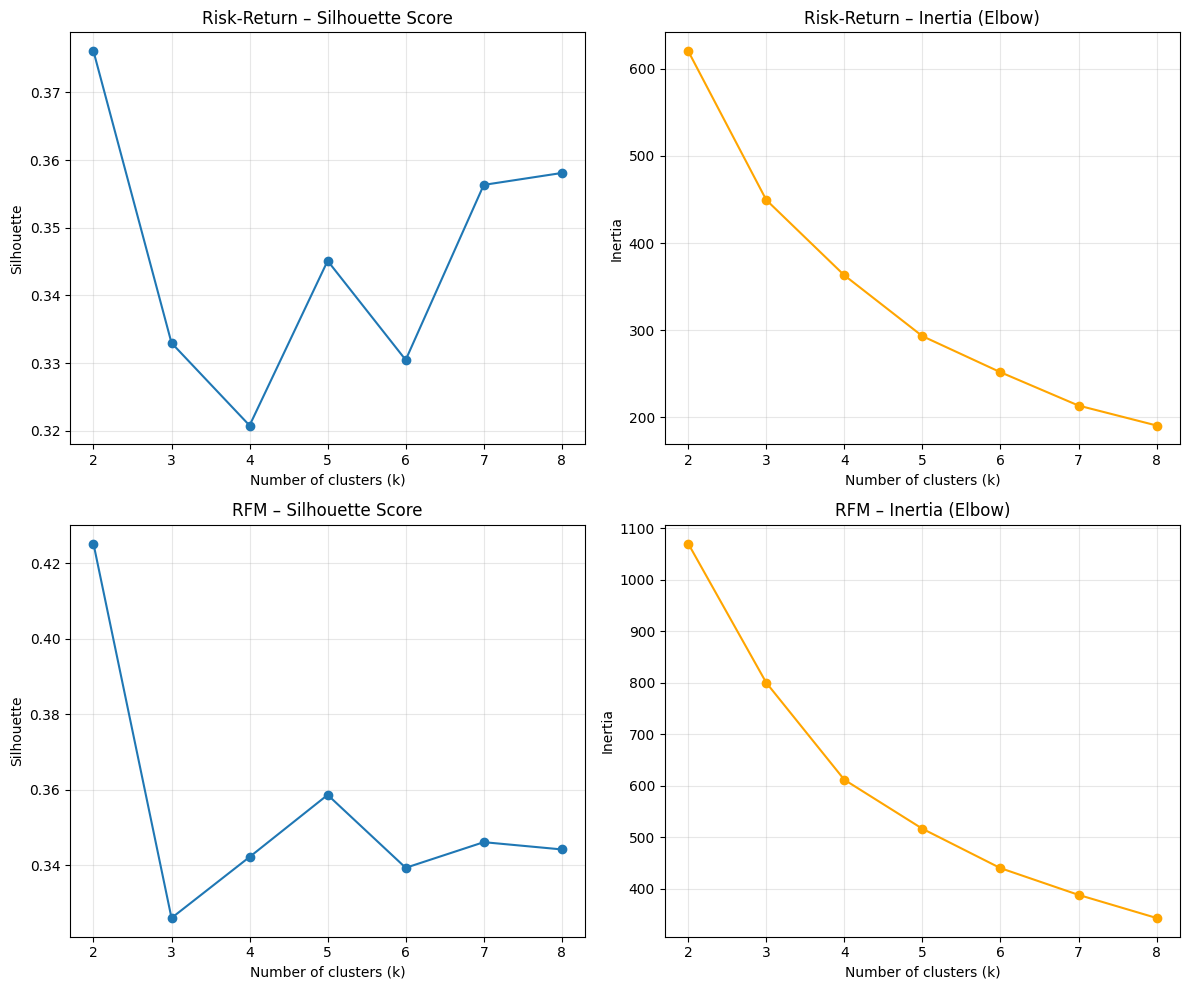

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Risk-Return – Silhouette
axes[0,0].plot(eval_risk_km["k"], eval_risk_km["silhouette"], marker="o")
axes[0,0].set_title("Risk-Return – Silhouette Score")
axes[0,0].set_xlabel("Number of clusters (k)")
axes[0,0].set_ylabel("Silhouette")
axes[0,0].grid(True, alpha=0.3)

# Risk-Return – Inertia
axes[0,1].plot(eval_risk_km["k"], eval_risk_km["inertia"], marker="o", color="orange")
axes[0,1].set_title("Risk-Return – Inertia (Elbow)")
axes[0,1].set_xlabel("Number of clusters (k)")
axes[0,1].set_ylabel("Inertia")
axes[0,1].grid(True, alpha=0.3)

# RFM – Silhouette
axes[1,0].plot(eval_rfm_km["k"], eval_rfm_km["silhouette"], marker="o")
axes[1,0].set_title("RFM – Silhouette Score")
axes[1,0].set_xlabel("Number of clusters (k)")
axes[1,0].set_ylabel("Silhouette")
axes[1,0].grid(True, alpha=0.3)

# RFM – Inertia
axes[1,1].plot(eval_rfm_km["k"], eval_rfm_km["inertia"], marker="o", color="orange")
axes[1,1].set_title("RFM – Inertia (Elbow)")
axes[1,1].set_xlabel("Number of clusters (k)")
axes[1,1].set_ylabel("Inertia")
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("kmeans_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

Choose the final k and fit the models

In [ ]:
# ----- Choose k (example values – replace with your best ones) -----
best_k_risk = 4
best_k_rfm  = 3

# ----- Fit final models -----
kmeans_risk = KMeans(n_clusters=best_k_risk, n_init=20, random_state=42)
labels_risk_km = kmeans_risk.fit_predict(X_risk_scaled)

kmeans_rfm = KMeans(n_clusters=best_k_rfm, n_init=20, random_state=42)
labels_rfm_km = kmeans_rfm.fit_predict(X_rfm_scaled)

# Add labels to the dataframes
risk_return["cluster_kmeans"] = labels_risk_km
rfm["cluster_kmeans"] = labels_rfm_km

print("Risk-Return K-means cluster sizes:")
print(risk_return["cluster_kmeans"].value_counts().sort_index())

print("\nRFM K-means cluster sizes:")
print(rfm["cluster_kmeans"].value_counts().sort_index())

Risk-Return K-means cluster sizes:
cluster_kmeans
0    164
1     52
2    146
3    126
Name: count, dtype: int64

RFM K-means cluster sizes:
cluster_kmeans
0    275
1    150
2     63
Name: count, dtype: int64


Save the results

In [ ]:
risk_return.to_csv("risk_return_with_kmeans.csv", index=False)
rfm.to_csv("rfm_with_kmeans.csv", index=False)

print("K-means cluster assignments saved.")

K-means cluster assignments saved.


**Task 2.4 – Cluster profiles and algorithm comparison**

Load the clustered data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

risk_return = pd.read_csv("risk_return_with_kmeans.csv")
rfm = pd.read_csv("rfm_with_kmeans.csv")

# Also load the agglomerative labels if you saved them earlier
# If not, you can re-create them or merge from previous files
print(risk_return.head())
print(rfm.head())

  ticker  mean_weekly_return  weekly_beta  cluster_kmeans
0    MMM            0.001142     0.869080               2
1    AOS            0.001991     1.042805               3
2    ABT            0.000971     0.583543               2
3   ABBV            0.003749     0.425365               2
4    ACN            0.002376     1.143300               3
  ticker  Recency  Frequency      Monetary  log_Monetary  cluster_kmeans
0    MMM       11          4  2.599146e+10     23.981034               0
1    AOS       11          2  4.748980e+09     22.281196               0
2    ABT       11          1  3.523027e+10     24.285172               1
3   ABBV       11          3  6.837054e+10     24.948208               1
4    ACN       11          2  5.199430e+10     24.674400               1


Create profiles in original units

Risk-Return profiles (K-means example)

In [ ]:
profile_risk = risk_return.groupby("cluster_kmeans").agg({
    "mean_weekly_return": ["mean", "median", "std", "count"],
    "weekly_beta": ["mean", "median", "std"]
}).round(4)

print("=== Risk-Return Cluster Profiles (original units) ===")
print(profile_risk)

=== Risk-Return Cluster Profiles (original units) ===
               mean_weekly_return                       weekly_beta          \
                             mean  median     std count        mean  median   
cluster_kmeans                                                                
0                          0.0042  0.0041  0.0013   164      0.9534  0.9564   
1                          0.0071  0.0069  0.0029    52      1.5324  1.5239   
2                          0.0016  0.0018  0.0015   146      0.5672  0.5603   
3                          0.0008  0.0011  0.0016   126      1.2179  1.1488   

                        
                   std  
cluster_kmeans          
0               0.1943  
1               0.3225  
2               0.1724  
3               0.2675  


RFM profiles (K-means example)

In [ ]:
profile_rfm = rfm.groupby("cluster_kmeans").agg({
    "Recency": ["mean", "median", "std", "count"],
    "Frequency": ["mean", "median", "std"],
    "Monetary": ["mean", "median"]
}).round(2)

print("\n=== RFM Cluster Profiles (original units) ===")
print(profile_rfm)


=== RFM Cluster Profiles (original units) ===
               Recency                     Frequency               \
                  mean median    std count      mean median   std   
cluster_kmeans                                                      
0                13.49   11.0   7.35   275      3.34    3.0  1.23   
1                14.11   11.0   7.90   150      2.89    3.0  1.25   
2                65.06   55.0  28.96    63      1.68    2.0  1.06   

                    Monetary                
                        mean        median  
cluster_kmeans                              
0               1.208456e+10  1.147936e+10  
1               8.241105e+10  4.245235e+10  
2               5.508714e+10  2.124212e+10  


**Labelled 2-D visualisation (PCA)**

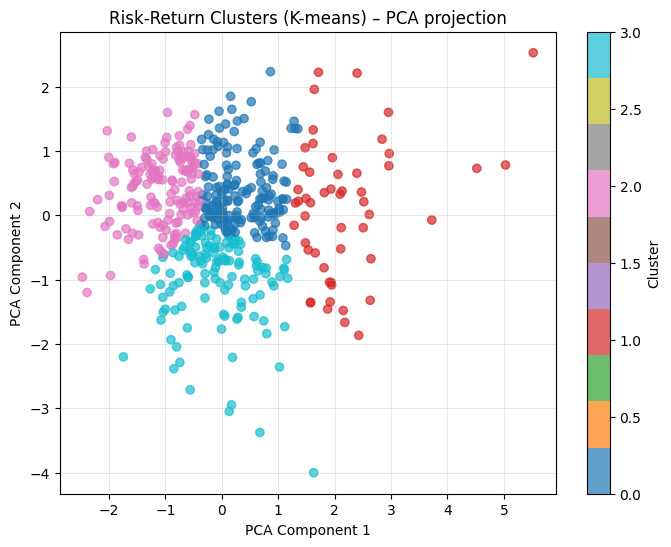

Explained variance (Risk-Return): [0.61 0.39]


In [ ]:
# ----- Risk-Return PCA -----
pca_risk = PCA(n_components=2, random_state=42)
X_risk_2d = pca_risk.fit_transform(np.load("X_risk_scaled.npy"))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_risk_2d[:, 0], X_risk_2d[:, 1],
                      c=risk_return["cluster_kmeans"], cmap="tab10", alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Risk-Return Clusters (K-means) – PCA projection")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.savefig("pca_risk_return_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

print("Explained variance (Risk-Return):", pca_risk.explained_variance_ratio_.round(3))

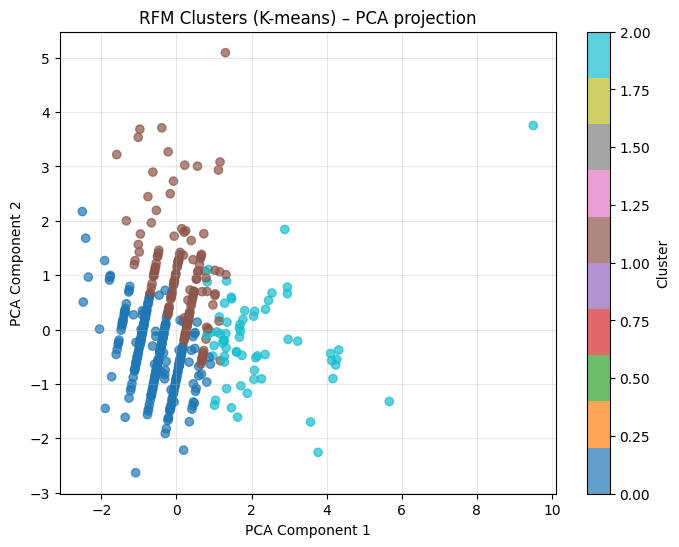

Explained variance (RFM): [0.458 0.336]


In [ ]:
# ----- RFM PCA -----
pca_rfm = PCA(n_components=2, random_state=42)
X_rfm_2d = pca_rfm.fit_transform(np.load("X_rfm_scaled.npy"))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_rfm_2d[:, 0], X_rfm_2d[:, 1],
                      c=rfm["cluster_kmeans"], cmap="tab10", alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("RFM Clusters (K-means) – PCA projection")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.3)
plt.savefig("pca_rfm_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

print("Explained variance (RFM):", pca_rfm.explained_variance_ratio_.round(3))

**Compare Agglomerative vs K-means on the same shares**

In [ ]:
# Example comparison (assuming you have both sets of labels)
# Merge the two label sets

comparison = risk_return[["ticker", "cluster_kmeans"]].merge(
    # replace with your agglomerative file
    pd.read_csv("risk_return_with_agg_clusters.csv")[["ticker", "cluster_agg"]],
    on="ticker"
)

# Contingency table
contingency = pd.crosstab(comparison["cluster_kmeans"], comparison["cluster_agg"])
print("Contingency table (K-means vs Agglomerative) – Risk-Return:")
print(contingency)

# You can also calculate Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(comparison["cluster_kmeans"], comparison["cluster_agg"])
print(f"\nAdjusted Rand Index: {ari:.3f}")

Contingency table (K-means vs Agglomerative) – Risk-Return:
cluster_agg      1   2   3    4
cluster_kmeans                 
0                3  24   5  132
1                0   0  30   22
2               53  93   0    0
3               80   0   0   46

Adjusted Rand Index: 0.377


**Task 2.5 – RFM Sensitivity and Correlated Inputs**

2.5.1 Correlation analysis

Correlation matrix (R, F, log_Monetary):
              Recency  Frequency  log_Monetary
Recency         1.000     -0.346         0.152
Frequency      -0.346      1.000         0.013
log_Monetary    0.152      0.013         1.000


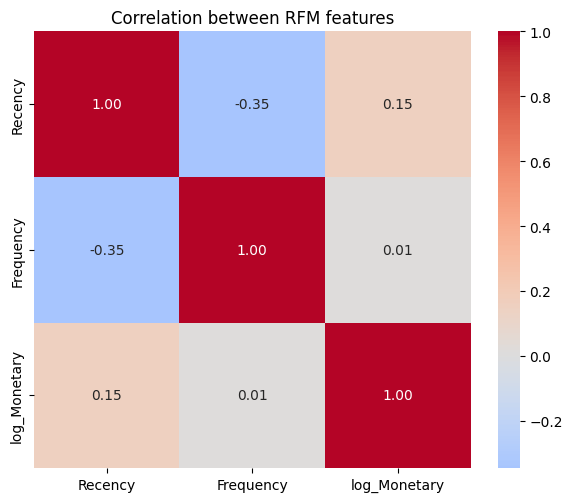

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

rfm = pd.read_csv("matrix_rfm.csv")

# We already created log_Monetary earlier
rfm["log_Monetary"] = np.log1p(rfm["Monetary"])

# Correlation matrix
corr = rfm[["Recency", "Frequency", "log_Monetary"]].corr()
print("Correlation matrix (R, F, log_Monetary):")
print(corr.round(3))

# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation between RFM features")
plt.tight_layout()
plt.savefig("rfm_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**2.5.2 Removal of Monetary**

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

# ----- Original RFM solution (with Monetary) -----
# Assume you already have the labels from Task 2.2
rfm_full = pd.read_csv("rfm_with_agg_clusters.csv")   # contains cluster_agg
original_labels = rfm_full["cluster_agg"].values
best_k = rfm_full["cluster_agg"].nunique()
print("Original k:", best_k)

# ----- Reduced feature matrix (R + F only) -----
X_reduced = rfm[["Recency", "Frequency"]].values

scaler_reduced = StandardScaler()
X_reduced_scaled = scaler_reduced.fit_transform(X_reduced)

# ----- Re-run Ward clustering -----
Z_reduced = linkage(X_reduced_scaled, method="ward", metric="euclidean")
labels_reduced = fcluster(Z_reduced, t=best_k, criterion="maxclust")

# ----- Membership comparison -----
ari = adjusted_rand_score(original_labels, labels_reduced)
print(f"Adjusted Rand Index (with vs without Monetary): {ari:.3f}")

# Add the new labels
rfm_full["cluster_no_Monetary"] = labels_reduced

Original k: 3
Adjusted Rand Index (with vs without Monetary): 0.265


Compare traded-value profiles

In [ ]:
print("=== Average Monetary by original clusters ===")
print(rfm_full.groupby("cluster_agg")["Monetary"].agg(["mean", "median", "count"]).round(0))

print("\n=== Average Monetary by reduced clusters (R+F only) ===")
print(rfm_full.groupby("cluster_no_Monetary")["Monetary"].agg(["mean", "median", "count"]).round(0))

=== Average Monetary by original clusters ===
                     mean        median  count
cluster_agg                                   
1            4.836432e+10  2.124212e+10     85
2            6.993615e+10  3.424691e+10    180
3            1.101312e+10  1.013983e+10    223

=== Average Monetary by reduced clusters (R+F only) ===
                             mean        median  count
cluster_no_Monetary                                   
1                    4.630362e+10  2.013167e+10     89
2                    3.433790e+10  1.769899e+10    125
3                    3.920490e+10  1.476031e+10    274
